In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [3]:
%pip install -U pip setuptools wheel
%pip install -U numpy pandas scikit-learn
%pip install -U lifelines scikit-survival

  Using cached lifelines-0.30.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached scikit_survival-0.27.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (7.0 kB)
  Using cached pandas-2.3.3-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (91 kB)
  Using cached autograd-gamma-0.5.0.tar.gz (4.0 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 134.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 117.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 99.4 MB/s  0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4119 sha256=0f4d877b6ef4f1bf12f1a9257640b07023d4262691cfbc16141801ce63e7b1a1
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd

In [4]:
import os
import pickle
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index

from sksurv.util import Surv
from sksurv.metrics import integrated_brier_score, cumulative_dynamic_auc

In [5]:
TRAIN_PATH = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/exp_1/hcc_exp1_train_selected.csv"
TEST_PATH = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/exp_1/hcc_exp1_test_selected.csv"
MODEL_PATH = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/exp_1/hcc_exp1_coxph_model.pkl"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/"

os.makedirs(RESULTS_DIR, exist_ok=True)

EVAL_TABLE_PATH = RESULTS_DIR + "hcc_exp1_coxph_test_predictions.csv"
METRICS_PATH = RESULTS_DIR + "hcc_exp1_coxph_metrics.csv"
KM_PLOT_PATH = RESULTS_DIR + "hcc_exp1_km_risk_groups.png"
RISK_HIST_PATH = RESULTS_DIR + "hcc_exp1_risk_histogram.png"
ORDERED_RISK_PATH = RESULTS_DIR + "hcc_exp1_ordered_risk_scores.png"
HRS_PATH = RESULTS_DIR + "hcc_exp1_top_hazard_ratios.csv"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"

In [6]:
train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

with open(MODEL_PATH, "rb") as file:
    cph_final = pickle.load(file)

train_data.shape, test_data.shape, cph_final

((1085, 32),
 (272, 32),
 <lifelines.CoxPHFitter: fitted with 1085 total observations, 444 right-censored observations>)

In [7]:
test_risk_scores = cph_final.predict_partial_hazard(test_data)

evaluation_df = test_data[[DURATION_COL, EVENT_COL]].copy()
evaluation_df["risk_score"] = test_risk_scores.values

evaluation_df.head()

,OS_MONTHS,OS_EVENT,risk_score
0,28.980,1,1.362369
1,5.952,1,3.197027
2,9.984,0,0.900178
3,23.652,1,3.366729
4,36.696,0,0.489888


Evaluate Test Concordance Index

In [8]:
test_c_index = concordance_index(
    test_data[DURATION_COL],
    -test_risk_scores,
    test_data[EVENT_COL]
)

print(f"Test Concordance Index: {test_c_index:.4f}")

Test Concordance Index: 0.7352


In [9]:
y_train = Surv.from_dataframe(EVENT_COL, DURATION_COL, train_data)
y_test = Surv.from_dataframe(EVENT_COL, DURATION_COL, test_data)

In [10]:
requested_time_points = np.array([1, 3, 5]) * 12
max_eval_time = min(train_data[DURATION_COL].max(), test_data[DURATION_COL].max())

time_points = requested_time_points[requested_time_points < max_eval_time]

if len(time_points) == 0:
    raise ValueError("No valid AUC time points are within observed follow-up range.")

print("AUC time points used (months):", time_points)

AUC time points used (months): [12 36 60]


In [11]:
time_grid = np.arange(1, int(max_eval_time))

if len(time_grid) == 0:
    raise ValueError("Time grid for IBS is empty. Check survival follow-up range.")

time_grid[:5], time_grid[-5:]

(array([1, 2, 3, 4, 5]), array([148, 149, 150, 151, 152]))

In [12]:
surv_df = cph_final.predict_survival_function(test_data, times=time_grid)
surv_probs = surv_df.T.values

surv_probs.shape

(272, 152)

Integrated Brier Score

In [13]:
ibs = integrated_brier_score(y_train, y_test, surv_probs, time_grid)
print(f"Integrated Brier Score: {ibs:.4f}")

Integrated Brier Score: 0.1216


AUC at 1, 3, 5 year

In [14]:
auc_scores, mean_auc = cumulative_dynamic_auc(
    y_train,
    y_test,
    test_risk_scores.values,
    time_points
)

for t, auc in zip(time_points, auc_scores):
    print(f"AUC at {int(t/12)} years: {auc:.4f}")

print(f"Mean time-dependent AUC: {mean_auc:.4f}")

AUC at 1 years: 0.8064
AUC at 3 years: 0.8395
AUC at 5 years: 0.7965
Mean time-dependent AUC: 0.8210


Plot Risk Score Distribution

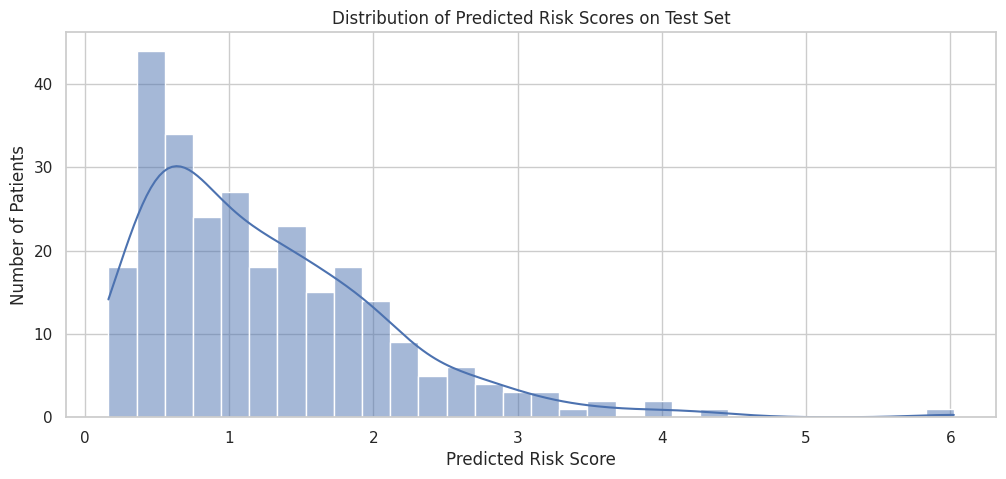

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
sns.histplot(evaluation_df["risk_score"], bins=30, kde=True)
plt.title("Distribution of Predicted Risk Scores on Test Set")
plt.xlabel("Predicted Risk Score")
plt.ylabel("Number of Patients")
plt.show()

1. Risk Score Distribution
The first graph, the histogram of predicted risk scores, shows how the CoxPH model spreads the test patients across different levels of predicted risk. Most patients are concentrated in the lower-to-middle risk range, while a smaller number extend into a long right tail with much higher scores.
What this means:

*  the model is not assigning the same risk to everyone

*  it is distinguishing between lower-risk and higher-risk patients

*   a few patients are predicted to have particularly high hazard, which is exactly what we would expect in a real clinical dataset

Why it matters for the research:



*   this shows the model has learned heterogeneity in the cohort

*   it supports the idea that genomic and clinical factors together can stratify survival risk

*  the right tail is especially useful because these are the patients the model sees as most vulnerable

Conclusion:
the CoxPH model generates a meaningful spread of risk scores rather than a collapsed or uniform prediction pattern



In [16]:
evaluation_df_sorted = evaluation_df.sort_values("risk_score", ascending=False).reset_index(drop=True)

evaluation_df_sorted.head(10)

,OS_MONTHS,OS_EVENT,risk_score
0,3.120,1,6.024843
1,4.536,0,4.389150
2,2.232,1,4.045044
3,7.716,1,4.014373
4,11.856,1,3.634509
5,8.412,1,3.564894
6,23.652,1,3.366729
7,5.952,1,3.197027
8,11.832,1,3.161581
9,11.472,0,3.126432


The “sorted highest-risk patients” table gives the top patients according to predicted hazard. These patients generally have:


*   very high risk scores
* short observed survival times
*   many death events (OS_EVENT = 1)

For example, the highest-risk patients show survival durations like 3.120, 2.232, 7.716, 8.412 months, which is consistent with the model calling them high risk.

What this means:
*  the model’s top-ranked patients are often the ones who indeed had poor survival outcomes
*   that is a practical sign that the ranking learned by CoxPH is clinically relevant

Why it matters for the research:
*   survival analysis is often more about ranking patients correctly than exact time prediction
*  this table demonstrates that the model is identifying a subgroup with clearly unfavorable prognosis

Conclusion:

 **the CoxPH ranking is behaving sensibly at the patient level**

Plot Ordered Risk Scores

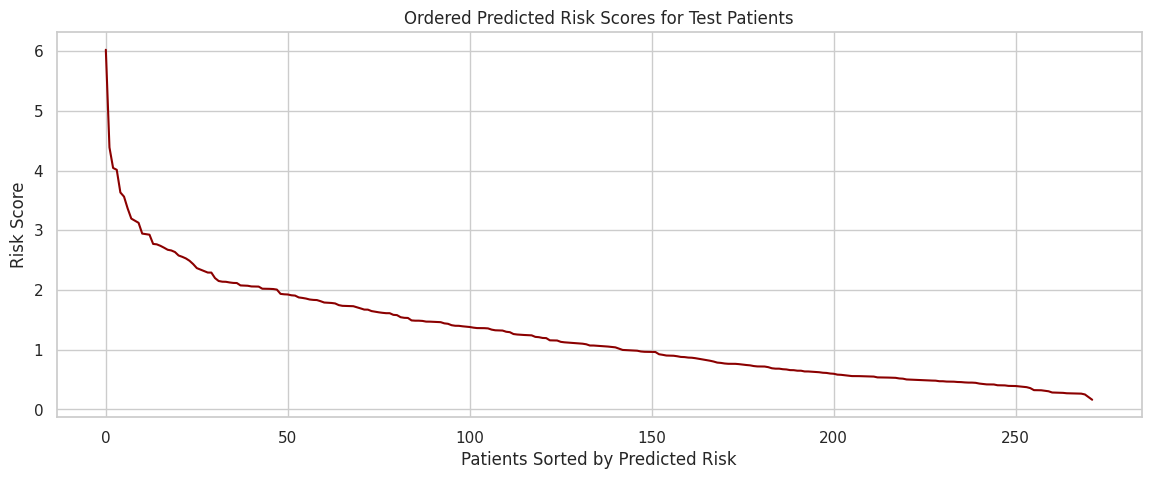

In [17]:
plt.figure(figsize=(14, 5))
plt.plot(evaluation_df_sorted["risk_score"].values, color="darkred")
plt.title("Ordered Predicted Risk Scores for Test Patients")
plt.xlabel("Patients Sorted by Predicted Risk")
plt.ylabel("Risk Score")
plt.show()

3. Ordered Risk Score Plot
The ordered risk score curve sorts all test patients from highest predicted risk to lowest. This gives a full picture of the model’s ranking behavior.
What this means:
the steep drop at the beginning shows a small subgroup with especially high risk
the gradual downward slope afterward shows a continuum of risk rather than only two extreme classes
the model is producing nuanced stratification across the test cohort
Why it matters for the research:
this is useful for understanding whether the model is only finding a few obvious cases or whether it captures broader risk variation
in your case, it appears to do both: a small extreme-risk group plus a wider gradient of survival risk
Conclusion:
the model provides a continuous and clinically usable risk ranking across patients

CoxPH Coefficient Summary

In [18]:
cox_summary = cph_final.summary[["coef", "exp(coef)", "p"]].sort_values("p")

print("Top CoxPH features by statistical significance:")
cox_summary.head(15)

Top CoxPH features by statistical significance:


,coef,exp(coef),p
covariate,,,
METASTASIS_Yes,0.409933,1.506716,8.998668e-08
RESECTION_MARGIN_R0,-0.302029,0.739317,4.961202e-04
CNA_CDKN2Ap16INK4A,-0.182373,0.833291,5.537024e-04
C_N_Yes,0.225169,1.252534,2.962213e-03
PRED_CATEGORY_Biliary class,0.327763,1.387860,3.102964e-03
MUT_ZFHX3,-0.622602,0.536547,3.343600e-03
PALLIATIVE_SYSTEMIC_THERPAY_No,-0.215542,0.806104,7.198927e-03
PRIMARY_SITE_Liver,-0.149108,0.861476,3.989528e-02
ADJUVANT_SYSTEMIC_THERAPY_Yes,-0.183255,0.832556,5.456081e-02


4. CoxPH Coefficient Summary
This table identifies which selected features contribute most strongly to survival risk. Since CoxPH is an interpretable model, this is one of the most valuable outputs.
Important interpretation rule:
exp(coef) > 1 means higher hazard, so worse expected survival

exp(coef) < 1 means lower hazard, so better expected survival tendency

Strong higher-risk signals:
METASTASIS_Yes with hazard ratio about 1.51

C_N_Yes with hazard ratio about 1.25

PRED_CATEGORY_Biliary class with hazard ratio about 1.39

Strong lower-risk signals:

RESECTION_MARGIN_R0 with hazard ratio about 0.74

CNA_CDKN2Ap16INK4A with hazard ratio about 0.83

MUT_ZFHX3 with hazard ratio about 0.54

PRIMARY_SITE_Liver with hazard ratio about 0.86

Why it matters for the research:

this gives biological and clinical meaning to the model

it shows that the model is not relying on nonsense patterns

clinically intuitive variables such as metastasis and resection margin emerge as important, which increases confidence in the pipeline

genomic features also appear in the top signals, supporting the value of molecular data in survival prediction

Conclusion:

the CoxPH model identifies a mix of clinical and genomic factors that are meaningfully associated with overall survival

Plot Top Hazard Ratios

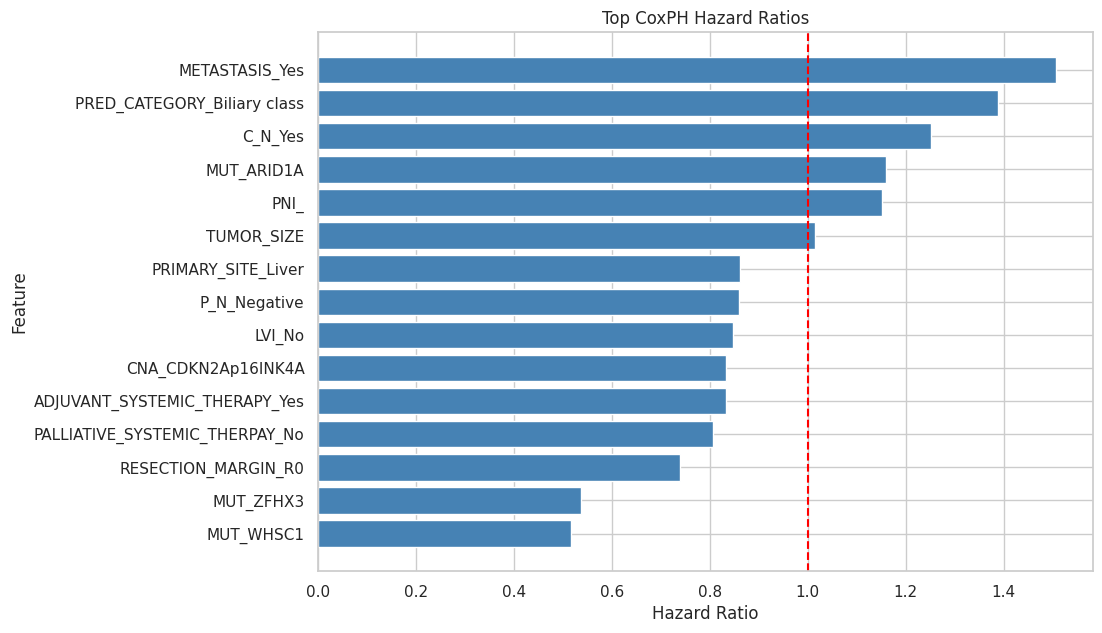

In [19]:
top_features = cox_summary.head(15).copy()
top_features = top_features.sort_values("exp(coef)")

plt.figure(figsize=(10, 7))
plt.barh(top_features.index, top_features["exp(coef)"], color="steelblue")
plt.axvline(x=1.0, color="red", linestyle="--")
plt.title("Top CoxPH Hazard Ratios")
plt.xlabel("Hazard Ratio")
plt.ylabel("Feature")
plt.show()

5. Top Hazard Ratio Plot
This graph is a visual version of the coefficient summary. The red dashed line at 1.0 is the neutral point.

How to read it:

bars to the right of 1.0 indicate features associated with higher risk


bars to the left of 1.0 indicate features associated with lower risk

What stands out:

METASTASIS_Yes is clearly one of the strongest adverse factors

PRED_CATEGORY_Biliary class and C_N_Yes also raise risk

RESECTION_MARGIN_R0, MUT_ZFHX3, and CNA_CDKN2Ap16INK4A appear protective in this fitted model

Why it matters for the research:

this makes the model interpretable to readers who may not want to study the
full coefficient table

it helps present the biological and clinical story in a visual way for the paper

Conclusion:
the model’s feature effects are directionally interpretable and support a biologically meaningful risk framework

Create High-Risk and Low-Risk Groups

In [20]:
median_risk = evaluation_df["risk_score"].median()

evaluation_df["risk_group"] = evaluation_df["risk_score"].apply(
    lambda x: "High risk" if x >= median_risk else "Low risk"
)

evaluation_df["risk_group"].value_counts()

,count
risk_group,
High risk,136
Low risk,136


Kaplan-Meier Curves by Predicted Risk Group

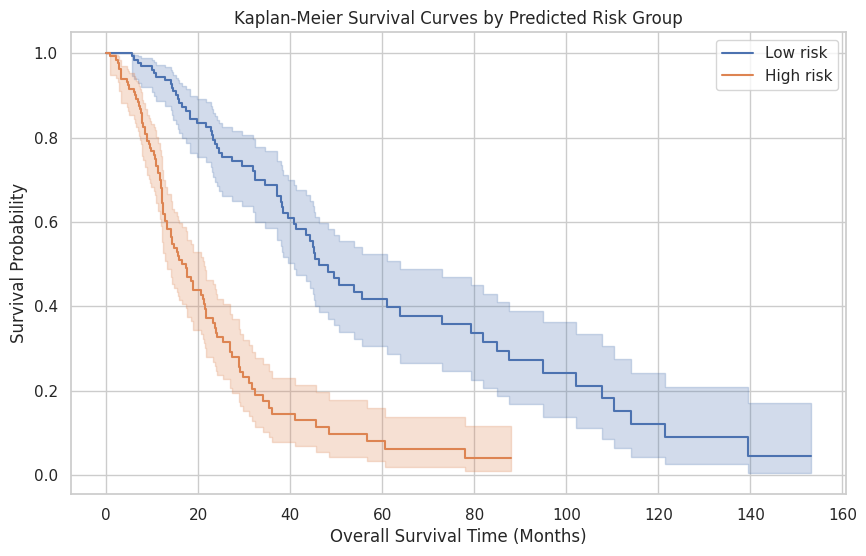

In [21]:
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group_name in ["Low risk", "High risk"]:
    group_df = evaluation_df[evaluation_df["risk_group"] == group_name]

    kmf.fit(
        durations=group_df[DURATION_COL],
        event_observed=group_df[EVENT_COL],
        label=group_name
    )
    kmf.plot_survival_function(ci_show=True)

plt.title("Kaplan-Meier Survival Curves by Predicted Risk Group")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.show()

. Kaplan-Meier Curves by Predicted Risk Group
This is one of the most important graphs in the notebook. Patients were split into High risk and Low risk groups using the median predicted risk score, and Kaplan-Meier curves were plotted for both groups.
What the graph shows:
the high-risk curve drops much faster
the low-risk curve remains higher for longer
the separation between the two groups is clear across follow-up time
What this means:
patients predicted by the model as high risk actually experience poorer survival
patients predicted as low risk survive longer on average
Why it matters for the research:
this is strong visual evidence that the model is clinically useful for stratification
it shows that CoxPH is not only producing numbers, but meaningfully separating prognosis groups
this kind of graph is very useful in a paper because it directly demonstrates survival discrimination
Conclusion:
the CoxPH model successfully stratifies the cohort into prognostically distinct survival groups

Confidence Bands Around Kaplan-Meier Curves
The shaded regions around the Kaplan-Meier lines show uncertainty intervals.
What this means:
narrower bands usually indicate more stable estimation in that part of the curve
wider bands later in time are normal because fewer patients remain under observation
Why it matters:
the clear separation between low-risk and high-risk groups is still visible despite uncertainty
this strengthens the conclusion that the model captures a real risk difference
Conclusion:
the group separation is not just cosmetic; it remains meaningful even when uncertainty is considered

Log-Rank Test Between Risk Groups

In [22]:
from lifelines.statistics import logrank_test

low_risk_df = evaluation_df[evaluation_df["risk_group"] == "Low risk"]
high_risk_df = evaluation_df[evaluation_df["risk_group"] == "High risk"]

logrank_result = logrank_test(
    low_risk_df[DURATION_COL],
    high_risk_df[DURATION_COL],
    event_observed_A=low_risk_df[EVENT_COL],
    event_observed_B=high_risk_df[EVENT_COL]
)

print("Log-rank test p-value:", logrank_result.p_value)

Log-rank test p-value: 3.650101065440847e-16


Add Survival Probabilities for Individual Patients

In [23]:
selected_times = [12, 24, 36, 60]

predicted_survival = cph_final.predict_survival_function(test_data, times=selected_times).T
predicted_survival.columns = [f"survival_prob_{t}m" for t in selected_times]

predicted_survival.head()

,survival_prob_12m,survival_prob_24m,survival_prob_36m,survival_prob_60m
0,0.751468,0.480833,0.291303,0.109250
1,0.511450,0.179368,0.055335,0.005540
2,0.827959,0.616423,0.442659,0.231549
3,0.493567,0.163732,0.047454,0.004205
4,0.902359,0.768510,0.641780,0.451056


Combine Survival Probability Outputs

In [24]:
patient_survival_summary = evaluation_df.copy().reset_index(drop=True)
patient_survival_summary = pd.concat(
    [patient_survival_summary, predicted_survival.reset_index(drop=True)],
    axis=1
)

patient_survival_summary.head()

,OS_MONTHS,OS_EVENT,risk_score,risk_group,survival_prob_12m,survival_prob_24m,survival_prob_36m,survival_prob_60m
0,28.980,1,1.362369,High risk,0.751468,0.480833,0.291303,0.109250
1,5.952,1,3.197027,High risk,0.511450,0.179368,0.055335,0.005540
2,9.984,0,0.900178,Low risk,0.827959,0.616423,0.442659,0.231549
3,23.652,1,3.366729,High risk,0.493567,0.163732,0.047454,0.004205
4,36.696,0,0.489888,Low risk,0.902359,0.768510,0.641780,0.451056


Plot Survival Curves for 3 Example Patients

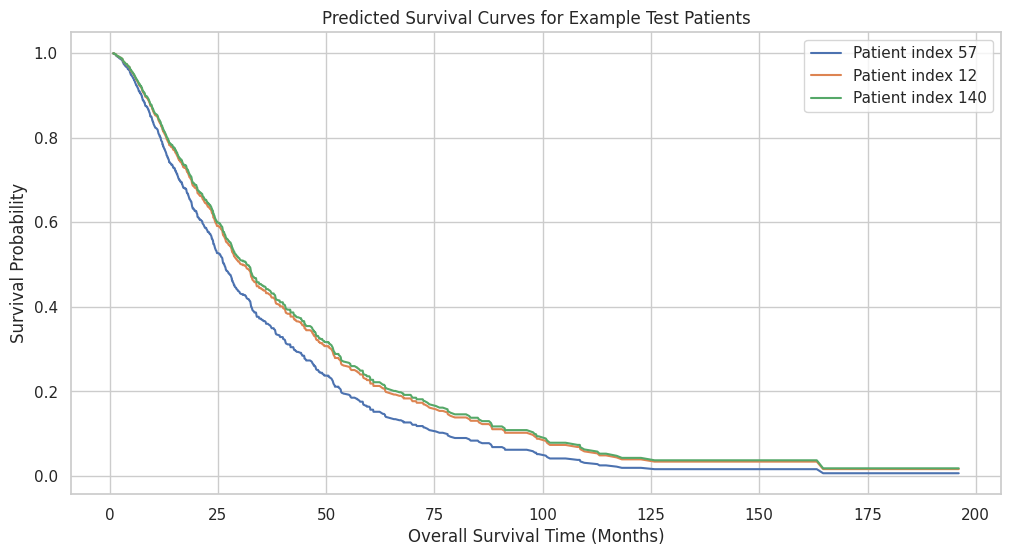

In [25]:
import random

random.seed(42)

example_patients = random.sample(list(test_data.index), 3)

example_survival_curves = cph_final.predict_survival_function(test_data.loc[example_patients])

plt.figure(figsize=(12, 6))

for patient_index in example_survival_curves.columns:
    plt.plot(
        example_survival_curves.index,
        example_survival_curves[patient_index],
        label=f"Patient index {patient_index}"
    )

plt.title("Predicted Survival Curves for Example Test Patients")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.legend()
plt.grid(True)
plt.show()

8. Predicted Survival Curves for Example Patients
This final graph shows individual predicted survival curves for a few example test patients.
What it means:
each line represents one patient’s predicted probability of remaining alive over time
a curve that drops faster indicates worse predicted prognosis
a curve that stays higher longer indicates better predicted prognosis
In your plot, one patient’s curve falls faster than the other two, meaning the model expects poorer survival for that patient.
Why it matters for the research:
this is the patient-level view of survival prediction
it shows how the model can be used beyond group summaries
this becomes especially important later for XAI, because once you explain why a specific patient has a steeper or flatter curve, the model becomes much more clinically interpretable
Conclusion:
the model can generate individualized survival trajectories, which is valuable for patient-level interpretation and future XAI work

Save Evaluation Results

In [26]:
patient_survival_summary.to_csv(EVAL_TABLE_PATH, index=False)

In [27]:
metrics_rows = [
    {"metric": "C-index", "value": test_c_index},
    {"metric": "IBS", "value": ibs},
]

for t, auc in zip(time_points, auc_scores):
    metrics_rows.append({"metric": f"AUC_{int(t/12)}_year", "value": auc})

metrics_rows.append({"metric": "Mean_time_dependent_AUC", "value": mean_auc})
metrics_rows.append({"metric": "Log-rank_p_value", "value": logrank_result.p_value})

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(METRICS_PATH, index=False)

metrics_df

,metric,value
0,C-index,7.351944e-01
1,IBS,1.216021e-01
2,AUC_1_year,8.064448e-01
3,AUC_3_year,8.394854e-01
4,AUC_5_year,7.965383e-01
5,Mean_time_dependent_AUC,8.209662e-01
6,Log-rank_p_value,3.650101e-16


In [28]:
EVAL_TABLE_PATH, METRICS_PATH

('/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_coxph_test_predictions.csv',
 '/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/exp_1/hcc_exp1_coxph_metrics.csv')

**Evaluation Summary**

The CoxPH evaluation notebook ran successfully on the held-out `exp_1` test set and shows that the trained model is performing well across both discrimination and survival-group separation. The model reached a test C-index of `0.7352`, which means it correctly ranks higher-risk versus lower-risk patients about 73.5% of the time on unseen data. That is a strong result for a classical survival model and stays consistent with the training notebook outcome.

The advanced survival metrics also support this. The time-dependent AUC was `0.8064` at 1 year, `0.8395` at 3 years, and `0.7965` at 5 years, with a mean time-dependent AUC of `0.8210`. These values suggest the model is especially good at separating patients around the medium-term survival horizon, with the best discrimination around 3 years. The Integrated Brier Score was `0.1216`, which indicates reasonably good overall survival probability calibration and prediction accuracy over follow-up time. Lower IBS is better, so this is a favorable value.

The feature summary shows that the CoxPH model is relying on clinically sensible signals. Stronger adverse-risk features include `METASTASIS_Yes`, `C_N_Yes`, and `PRED_CATEGORY_Biliary class`, while protective or lower-risk associations include `RESECTION_MARGIN_R0`, `CNA_CDKN2Ap16INK4A`, `MUT_ZFHX3`, and `PRIMARY_SITE_Liver`. That matters because it tells us the model is not just performing numerically well, but is also aligning with meaningful clinical and biological patterns.

The patient-level prediction table adds the practical interpretation layer. For each test patient, the notebook saved:
- observed survival time in `OS_MONTHS`
- event indicator in `OS_EVENT`
- predicted CoxPH `risk_score`
- assigned `risk_group`
- predicted survival probabilities at `12`, `24`, `36`, and `60` months

So for example, a high-risk patient with a large risk score gets much lower predicted survival probabilities across time, while a low-risk patient keeps higher survival probabilities. That is exactly the kind of output we want for downstream comparison and reporting.

Finally, the Kaplan-Meier risk-group analysis confirmed that the model’s risk stratification is statistically meaningful. The log-rank p-value was `3.65e-16`, which is extremely small, meaning the predicted high-risk and low-risk groups have clearly different survival curves. In plain terms, the CoxPH model is not only ranking patients well, but also separating them into survival groups with real prognostic distinction.

Overall, this notebook shows that the `exp_1` CoxPH baseline remains strong after the updated evaluation pipeline. It performs well on C-index, AUC, IBS, and risk-group survival separation, and it produces patient-level survival outputs that we can directly carry forward into the DeepSurv comparison.